In [1]:
import os
import warnings

warnings.filterwarnings('ignore', message = ".*Glyph.*")

import gc, json, random, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

QUICK = True

BASE = Path.cwd()
ASSETS = BASE / 'assets'
DATA = BASE / 'data' / 'knowledge'
WORK = BASE / 'work'

for d in ('models', 'chroma', 'images'):
    (WORK / d).mkdir(parents = True, exist_ok = True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

IMG_TYPE = torch.float16 if DEVICE in ('cuda', 'mps') else torch.float32

installed = {f.name for f in font_manager.fontManager.ttflist}
for name in {'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR'}:
    if name in installed:
        plt.rcParams['font.family'] = name
        break

plt.rcParams['axes.unicode_minus'] = False

cuda


In [2]:
def set_seed(seed = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def free_memory():
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

def show_images(images, titles = None, cols = None, size = 3.2):
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize = (size * cols, size * rows), squeeze = False)

    for ax in axes.ravel(): ax.axis('off')

    for i, img in enumerate(images):
        axes.ravel()[i].imshow(img)

        if titles: axes.ravel()[i].set_title(titles[i], fontsize = 10)

    plt.tight_layout(); plt.show()

set_seed(42)
print(DEVICE, QUICK)
print(BASE)

cuda True
c:\Users\KDS-11\Documents\KDT-17-CLASS\rag


In [3]:
from transformers import AutoTokenizer, AutoModel

EMB_NAME = 'intfloat/multilingual-e5-small'
tok = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).eval().to(DEVICE)

sentences = ['나는 강아지를 정말 좋아합니다.', '금요일은 행복한 날이에요.']
enc = tok(sentences, padding = True, truncation = True, return_tensors = 'pt')

print(enc['input_ids'])
for i in range(len(sentences)):
    print(tok.convert_ids_to_tokens(enc['input_ids'][i]))

print(enc['attention_mask'])

c:\Users\KDS-11\Documents\KDT-17-CLASS\rag\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3726.02it/s]


tensor([[     0,  37231,  13564,   3222,  49067,  34682,  67738,   8642,      5,
              2],
        [     0,  36527,   5144,   1599,    697, 169384,  21858, 190278,      5,
              2]])
['<s>', '▁나는', '▁강', '아', '지를', '▁정말', '▁좋아', '합니다', '.', '</s>']
['<s>', '▁금', '요', '일', '은', '▁행복한', '▁날', '이에요', '.', '</s>']
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


In [4]:
with torch.no_grad():
    out = emb_model(**enc.to(DEVICE))

emb = out.last_hidden_state

print(tuple(emb.shape))
print(emb[0, 0, :6].cpu().numpy().round(3))

(2, 10, 384)
[ 0.166 -0.037 -0.112 -0.297  0.428 -0.065]


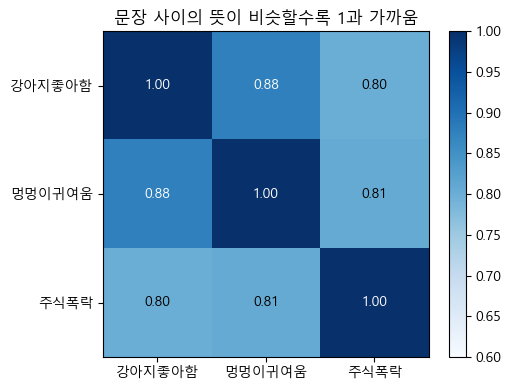

In [5]:
import torch.nn.functional as F

def embed(texts, prefix = 'query', batch_size = 32):
    vectors = []
    for i in range(0, len(texts), batch_size):
        batch = [prefix + t for t in texts[i:i + batch_size]]
        enc = tok(batch, padding = True, truncation = True, max_length = 512, return_tensors = 'pt').to(DEVICE)
        with torch.no_grad():
            hidden = emb_model(**enc).last_hidden_state

        mask = enc['attention_mask'].unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        vectors.append(F.normalize(pooled, p = 2, dim = 1).cpu())

    return torch.cat(vectors)

texts = ['나는 강아지를 정말 좋아해요.',
         '우리 집 멍멍이가 세상에서 제일 귀여워요.',
         '주식 시장이 크게 폭락했습니다.']

vecs = embed(texts)
sim = vecs @ vecs.T

fig, ax = plt.subplots(figsize = (5.2, 4))
im = ax.imshow(sim.numpy(), cmap = 'Blues', vmin = 0.6, vmax = 1)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(['강아지좋아함', '멍멍이귀여움', '주식폭락'])
ax.set_yticklabels(['강아지좋아함', '멍멍이귀여움', '주식폭락'])

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha = "center", va = "center", color = "white" if sim[i, j] > 0.85 else "black")

ax.set_title('문장 사이의 뜻이 비슷할수록 1과 가까움')
plt.colorbar(im), plt.tight_layout(); plt.show()

In [6]:
from torchvision import transforms, models

img = Image.open(ASSETS / 'puppy.jpg').convert('RGB')
x = transforms.ToTensor()(img)

weights = models.ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights = weights).eval()
labels = weights.meta['categories']

batch = weights.transforms()(img).unsqueeze(0)

with torch.no_grad():
    logits = resnet(batch)

probs = torch.softmax(logits, dim = 1)[0]
top_p, top_i = probs.topk(5)

for p, i in zip(top_p, top_i):
    print(f"{labels[i]:25s} {p:6.1%}")

entropy = - (probs * torch.log(probs + 1e-10)).sum()

Labrador retriever         23.9%
Sealyham terrier           18.3%
tennis ball                11.6%
Great Pyrenees             11.6%
golden retriever            7.6%


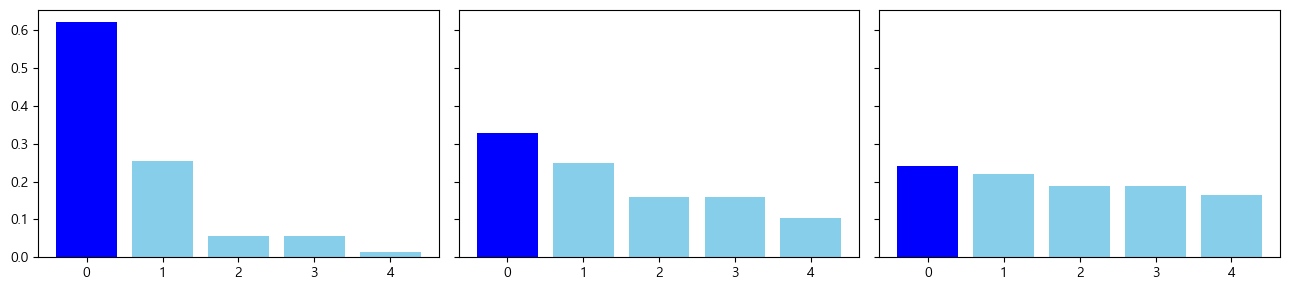

In [7]:
top_logits = logits[0].topk(5).values

fig, axes = plt.subplots(1, 3, figsize = (13, 3), sharey = True)

for ax, T in zip(axes, (0.3, 1.0, 3.0)):
    p = torch.softmax(top_logits / T, dim = 0)
    ax.bar(range(5), p.numpy(), color = ['blue'] + ['skyblue'] * 4)

plt.tight_layout(); plt.show()

# 온도가 0.3, 1.0, 3.0 -> 온도에 따라서 결과가 달라짐.

In [8]:
from huggingface_hub import HfApi, hf_hub_download, ModelCard

api = HfApi()

try:
    info = api.model_info(EMB_NAME)
    print(info.id)
    print(info.pipeline_tag)
    print(info.downloads)
    print(info.tags)

    for m in api.list_models(filter = 'text-classification', sort = 'downloads', limit = 5):
        print(m.id)

except Exception as e:
    print('Failed')

intfloat/multilingual-e5-small
sentence-similarity
11268724
['sentence-transformers', 'pytorch', 'onnx', 'safetensors', 'openvino', 'bert', 'mteb', 'Sentence Transformers', 'sentence-similarity', 'multilingual', 'af', 'am', 'ar', 'as', 'az', 'be', 'bg', 'bn', 'br', 'bs', 'ca', 'cs', 'cy', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu', 'fa', 'fi', 'fr', 'fy', 'ga', 'gd', 'gl', 'gu', 'ha', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'is', 'it', 'ja', 'jv', 'ka', 'kk', 'km', 'kn', 'ko', 'ku', 'ky', 'la', 'lo', 'lt', 'lv', 'mg', 'mk', 'ml', 'mn', 'mr', 'ms', 'my', 'ne', 'nl', 'no', 'om', 'or', 'pa', 'pl', 'ps', 'pt', 'ro', 'ru', 'sa', 'sd', 'si', 'sk', 'sl', 'so', 'sq', 'sr', 'su', 'sv', 'sw', 'ta', 'te', 'th', 'tl', 'tr', 'ug', 'uk', 'ur', 'uz', 'vi', 'xh', 'yi', 'zh', 'arxiv:2402.05672', 'arxiv:2108.08787', 'arxiv:2104.08663', 'arxiv:2210.07316', 'license:mit', 'model-index', 'eval-results', 'text-embeddings-inference', 'endpoints_compatible', 'region:us']
cross-encoder/ms-marco-MiniLM-L6-v2
BA

In [9]:
## 2601006

try:
    card = ModelCard.load(EMB_NAME)
    print(card.text[:500].strip())

except Exception as e:
    print('Failed!')

cfg = json.load(open(hf_hub_download(EMB_NAME, 'config.json')))

for k in ('model_type', 'num_hidden_layers', 'hidden_size', 'num_attention_heads', 'vocab_size', 'max_position_embeddings'):
    print(cfg[k])

## Multilingual-E5-small

[Multilingual E5 Text Embeddings: A Technical Report](https://arxiv.org/pdf/2402.05672).
Liang Wang, Nan Yang, Xiaolong Huang, Linjun Yang, Rangan Majumder, Furu Wei, arXiv 2024

This model has 12 layers and the embedding size is 384.

## Usage

Below is an example to encode queries and passages from the MS-MARCO passage ranking dataset.

```python
import torch.nn.functional as F

from torch import Tensor
from transformers import AutoTokenizer, AutoModel


def average
bert
12
384
12
250037
512


In [10]:
from transformers import pipeline, set_seed

en_sentiment = pipeline('sentiment-analysis',
                        model = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english',
                        device = DEVICE)

for s in ['I love working with transformers!', 'This was the worst meeting ever']:
    print(s, en_sentiment(s)[0])

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1181.89it/s]


I love working with transformers! {'label': 'POSITIVE', 'score': 0.999541163444519}
This was the worst meeting ever {'label': 'NEGATIVE', 'score': 0.999785840511322}


In [11]:
generator = pipeline('text-generation', model = 'gpt2', device = DEVICE)
prompt = 'The future of AI is'

for temp in (0.3, 1.5):
    set_seed(7)
    out = generator(prompt, max_new_tokens = 30, do_sample = True, temperature = temp, top_k = 50)
    print(temp, out[0]['generated_text'])

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 509.65it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature', 'top_k', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=30) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_wil

0.3 The future of AI is not yet clear. But it is possible that AI will be able to solve many problems, and that it will be able to solve many problems at once
1.5 The future of AI is not always on-watch; it's changing how technology is perceived today and, at the end of that era it may just break down into smaller and


In [12]:
from transformers import AutoModelForSequenceClassification

name = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
tk = AutoTokenizer.from_pretrained(name)
clf = AutoModelForSequenceClassification.from_pretrained(name).eval()

text = 'The club meeting was surprisingly fun!'
enc = tk(text, return_tensors = 'pt')

with torch.no_grad():
    logits = clf(**enc).logits

probs = torch.softmax(logits, dim = -1)[0]

print(tk.convert_ids_to_tokens(enc['input_ids'][0]))
print(logits[0].numpy().round(2))
print(probs.numpy().round(3))
print(clf.config.id2label, clf.config.id2label[int(probs.argmax())])

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1299.95it/s]

['[CLS]', 'the', 'club', 'meeting', 'was', 'surprisingly', 'fun', '!', '[SEP]']
[-4.28  4.61]
[0. 1.]
{0: 'NEGATIVE', 1: 'POSITIVE'} POSITIVE


In [13]:
bert_tok = AutoTokenizer.from_pretrained('bert-base-uncased')
print(bert_tok.tokenize('The ultramarathoner prequalified for the immunohistochemistry conference'))

for s in ['인공지능비서', '머신러닝', '동아리의해커톤']:
    print(f"다국어 e5: {s!r:14} ->", tok.tokenize(s))

['the', 'ultra', '##mara', '##th', '##one', '##r', 'pre', '##qual', '##ified', 'for', 'the', 'im', '##mun', '##oh', '##isto', '##chemist', '##ry', 'conference']
다국어 e5: '인공지능비서'       -> ['▁인공지능', '비', '서']
다국어 e5: '머신러닝'         -> ['▁머', '신', '러', '닝']
다국어 e5: '동아리의해커톤'      -> ['▁동', '아리', '의', '해', '커', '톤']


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3297.17it/s]


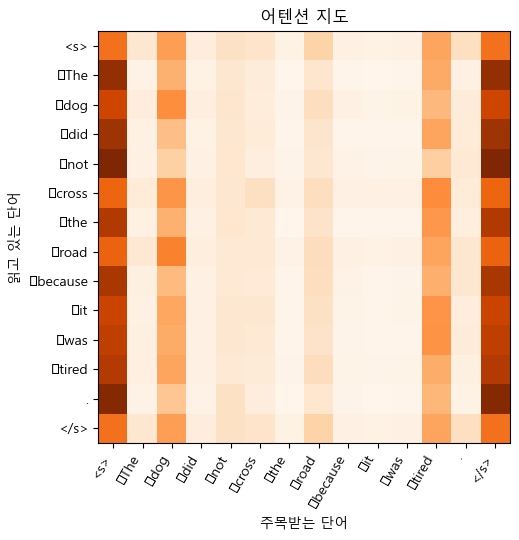

In [14]:
att_model = AutoModel.from_pretrained(EMB_NAME, attn_implementation = 'eager').eval()
sent = 'The dog did not cross the road because it was tired.'
enc = tok(sent, return_tensors = 'pt')

with torch.no_grad():
    att = att_model(**enc, output_attentions = True).attentions[-1][0].mean(0)

tokens = tok.convert_ids_to_tokens(enc['input_ids'][0])

fig, ax = plt.subplots(figsize = (6.5, 5.5))
ax.imshow(att.numpy(), cmap = 'Oranges')
ax.set_xticks(range(len(tokens)))
ax.set_xticklabels(tokens, rotation = 60, ha = 'right')
ax.set_yticks(range(len(tokens)))
ax.set_yticklabels(tokens)
ax.set_xlabel('주목받는 단어')
ax.set_ylabel('읽고 있는 단어')
ax.set_title('어텐션 지도')
plt.tight_layout()
plt.show()

del att_model
free_memory()

In [15]:
from datasets import load_dataset

nsmc = load_dataset('e9t/nsmc', revision = 'refs/convert/parquet')
print(nsmc)

N_TRAIN, N_EVAL = (3000, 1000) if QUICK else (30000, 5000)
train_raw = nsmc['train'].filter(lambda r: r['document'] is not None and len(r['document']) > 3).shuffle(seed = 42).select(range(N_TRAIN))
eval_raw = nsmc['test'].filter(lambda r: r['document'] is not None and len(r['document']) > 3).shuffle(seed = 42).select(range(N_EVAL))

print(len(train_raw), len(eval_raw))

for r in train_raw.select(range(5)):
    print(f"[{'긍정' if r['label'] else '부정'}] {r['document']}")

c:\Users\KDS-11\Documents\KDT-17-CLASS\rag\.venv\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\KDS-11\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\KDS-11\Documents\KDT-17-CLASS\rag\.venv\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingfa

DatasetDict({
    train: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 150000
    })
    test: Dataset({
        features: ['id', 'document', 'label'],
        num_rows: 50000
    })
})


Filter: 100%|██████████| 50000/50000 [00:00<00:00, 861398.43 examples/s]

3000 1000
[부정] 별점 주기도 참~~~~아깝다
[부정] 지루하다..
[부정] OOO기영화 볼것하나없는 최악영화
[긍정] 정말 재밌다....! 기억에 남는 작품..윤시윤...하하...대박이구나...!!!!!!!!!!!!!!
[긍정] 언제봐도 즐거운영화~


In [18]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

ID2LABEL = {0: '부정', 1: '긍정'}

def tokenize_batch(batch):
    return tok(batch['document'], truncation = True, max_length = 64)

train_ds = train_raw.map(tokenize_batch, batched = True, remove_columns = ['id', 'document'])
eval_ds = eval_raw.map(tokenize_batch, batched = True, remove_columns = ['id', 'document'])

def accuracy(eval_pred):
    logits, y = eval_pred

    return {'accuracy': float((np.argmax(logits, axis = -1) == y).mean())}

set_seed(42)
ft_model = AutoModelForSequenceClassification.from_pretrained(EMB_NAME, num_labels = 2, id2label = ID2LABEL, label2id = {v: k for k, v in ID2LABEL.items()})
args = TrainingArguments(output_dir = str(WORK / 'ckpt'), num_train_epochs = 2 if QUICK else 3, per_device_train_batch_size = 32,
                         per_device_eval_batch_size = 64, learning_rate = 5e-5, weight_decay = 0.01, eval_strategy = 'epoch',
                         save_strategy = 'no', logging_steps = 20, report_to = 'none', seed = 42)
trainer = Trainer(model = ft_model, args = args, train_dataset = train_ds, eval_dataset = eval_ds, data_collator = DataCollatorWithPadding(tok),
                  compute_metrics = accuracy)
base_acc = trainer.evaluate()['eval_accuracy']
print(f"파인튜닝 전 정확도: {base_acc:.1%}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2790.35it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-small
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training Loss,Validation Loss,Epoch,Accuracy
No log,0.693501,0,0.499000


파인튜닝 전 정확도: 49.9%


In [19]:
t0 = time.time()
trainer.train()

print(f"학습시간: {time.time() - t0:.0f}초")

ft_acc = trainer.evaluate()['eval_accuracy']
print(f"파인튜닝 후 정확도: {ft_acc:.1%}")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.507875,0.504557,0.775000
2,0.440180,0.486630,0.786000


학습시간: 21초


Training Loss,Validation Loss,Epoch,Accuracy
0.440180,0.486630,2,0.786000


파인튜닝 후 정확도: 78.6%


In [30]:
# 프롬프트 튜닝

import torch.nn as nn

class PromptTuningClassifier(nn.Module):
    def __init__(self, model_name, num_virtual_tokens = 20):
        super().__init__()
        self.backbone = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels = 2, id2label = ID2LABEL, label2id = {v: k for k, v in ID2LABEL.items()})
        self.backbone.requires_grad_(False)

        for p in self.backbone.classifier.parameters():
            p.requires_grad_(True)

        self.n = num_virtual_tokens
        word_emb = self.backbone.get_input_embeddings()
        init_ids = torch.randint(1000, 2000, (num_virtual_tokens, ))
        self.prompt = nn.Parameter(word_emb(init_ids).detach().clone().unsqueeze(0))

    def forward(self, input_ids, attention_mask, labels = None):
        b = input_ids.shape[0]
        word_emb = self.backbone.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([self.prompt.expand(b, -1, -1), word_emb], dim = 1)
        mask = torch.cat([torch.ones(b, self.n, device = attention_mask.device, dtype = attention_mask.dtype), attention_mask], dim = 1)

        return self.backbone(inputs_embeds = inputs_embeds, attention_mask = mask, labels = labels)

set_seed(42)
pt_model = PromptTuningClassifier(EMB_NAME).to(DEVICE)
n_train = sum(p.numel() for p in pt_model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in pt_model.parameters())

print("전체 파라미터:", n_total)
print("학습 대상:", n_train)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3033.03it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-small
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


전체 파라미터: 117662210
학습 대상: 8450


In [31]:
from torch.utils.data import DataLoader

collate = DataCollatorWithPadding(tok)
train_loader = DataLoader(train_ds, batch_size = 32, shuffle = True, collate_fn = collate)
eval_loader = DataLoader(eval_ds, batch_size = 64, collate_fn = collate)

def evaluate_pt(model):
    model.eval()
    correct = 0

    with torch.no_grad():
        for b in eval_loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            y = b.pop('labels')
            correct += (model(b['input_ids'], b['attention_mask']).logits.argmax(-1) == y).sum().item()

    return correct / len(eval_ds)

PT_EPOCHS = 4 if QUICK else 8
opt = torch.optim.AdamW([p for p in pt_model.parameters() if p.requires_grad], lr = 2e-2)
pt_losses = []

for epoch in range(PT_EPOCHS):
    pt_model.train()
    total = 0

    for b in train_loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        y = b.pop('labels')
        loss = pt_model(b['input_ids'], b['attention_mask'], labels = y).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(pt_model.parameters(), 1.0)
        opt.step()
        opt.zero_grad()
        total += loss.item()

    pt_losses.append(total / len(train_loader))
    print(epoch + 1, pt_losses, evaluate_pt(pt_model))

pt_acc = evaluate_pt(pt_model)
print(pt_acc)

1 [0.6819866464493123] 0.662
2 [0.6819866464493123, 0.5666359618623206] 0.71
3 [0.6819866464493123, 0.5666359618623206, 0.5329989429484022] 0.743
4 [0.6819866464493123, 0.5666359618623206, 0.5329989429484022, 0.5134290551885645] 0.739
0.739
